In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

print("NumPy :", np.__version__)
print("OpenCV:", cv2.__version__)


def show(img, title="", cmap="gray", vmin=0, vmax=255):
    """Display an image with Matplotlib (expects RGB order for color)."""
    plt.figure(figsize=(5, 5))
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    else:
        plt.imshow(img, interpolation="nearest")
    plt.title(title)
    plt.axis("off")
    plt.show()


def storage_bytes(M, N, k, channels=1):
    return M * N * k * channels / 8


def quantize(img, k):
    step = 256 // (2 ** k)
    return (img // step) * step + step // 2


I = data.camera()
M, N = I.shape
C = data.astronaut()


NumPy : 2.1.3
OpenCV: 4.14.0


# Task 1 - Pixels as numbers



=== Task 1 ===
Centre pixel I[256, 256] = 14


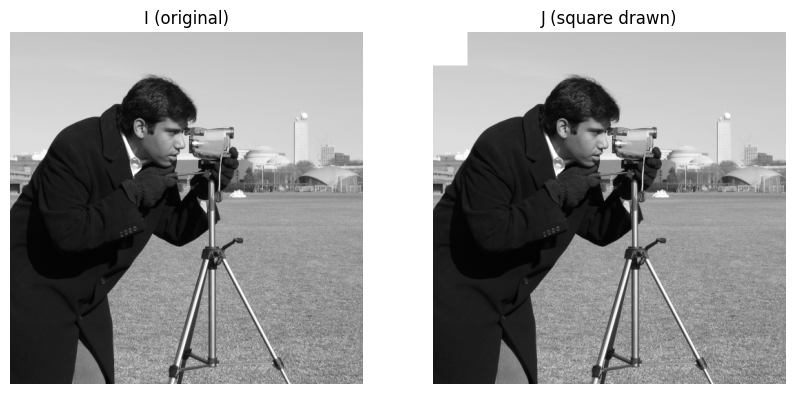

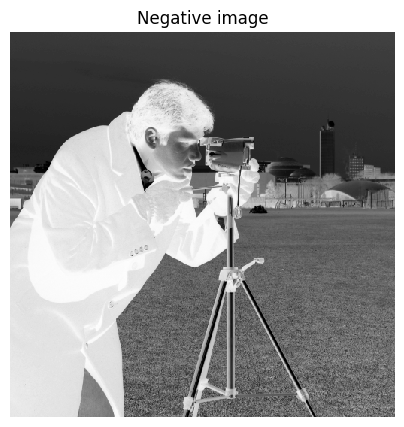

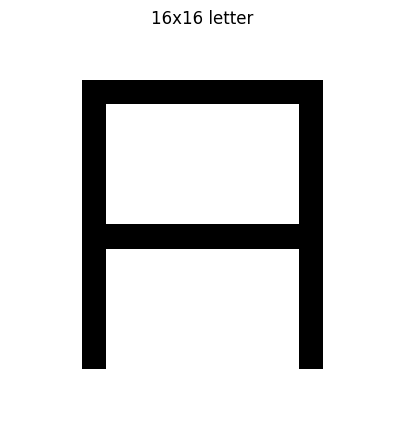

In [2]:
print("\n=== Task 1 ===")
# 1. centre pixel
print("Centre pixel I[256, 256] =", I[M // 2, N // 2])

# 2. copy + white 50x50 square
J = I.copy()
J[0:50, 0:50] = 255
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(I, cmap="gray", vmin=0, vmax=255); ax[0].set_title("I (original)")
ax[1].imshow(J, cmap="gray", vmin=0, vmax=255); ax[1].set_title("J (square drawn)")
for a in ax: a.axis("off")
plt.show()
# WHY .copy(): NumPy assignment (J = I) only creates a second NAME for the same
# array (a reference / view of the same memory). Editing J would also edit I.
# .copy() allocates new memory so the original stays untouched.

# 3. negative
Ineg = 255 - I           # uint8: 255 - x never goes below 0, so no overflow
show(Ineg, "Negative image")

# 4. 16x16 letter using only 0 and 255 (change the letter to your own initial)
letter = np.full((16, 16), 255, dtype=np.uint8)
letter[2:14, 3] = 0       # left stroke of "A"
letter[2:14, 12] = 0      # right stroke
letter[2, 4:12] = 0       # top bar
letter[8, 3:13] = 0       # middle bar
show(letter, "16x16 letter")


# Task 2 - Bit depth



=== Task 2 ===
camera 512x512, 8-bit gray : 262144.0 bytes
350x233, 24-bit color      : 244650.0 bytes
Actual array size in memory: 262144 bytes


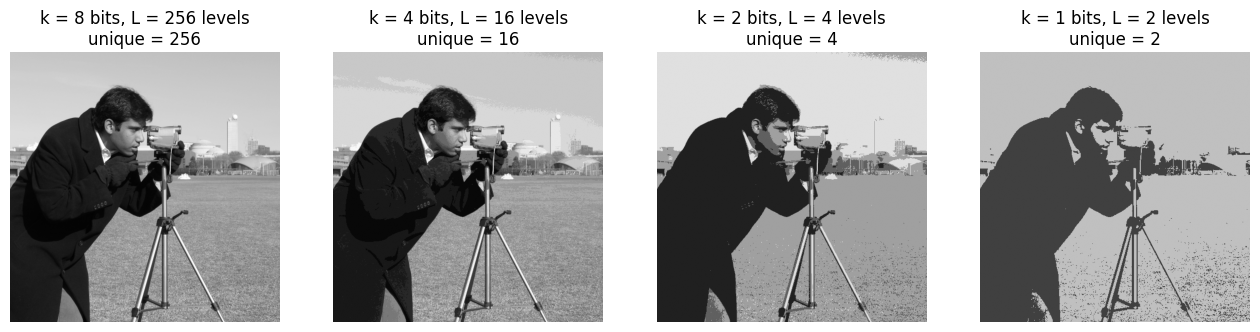

 k  L=2^k  unique     bytes      KiB
 8    256     256    262144    256.0
 7    128     128    229376    224.0
 6     64      64    196608    192.0
 5     32      32    163840    160.0
 4     16      16    131072    128.0
 3      8       8     98304     96.0
 2      4       4     65536     64.0
 1      2       2     32768     32.0


In [3]:
print("\n=== Task 2 ===")
print("camera 512x512, 8-bit gray :", storage_bytes(512, 512, 8), "bytes")
print("350x233, 24-bit color      :", storage_bytes(350, 233, 8, 3), "bytes")
print("Actual array size in memory:", I.nbytes, "bytes")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, [8, 4, 2, 1]):
    q = quantize(I, k)
    ax.imshow(q, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k} bits, L = {2**k} levels\nunique = {len(np.unique(q))}")
    ax.axis("off")
plt.show()

# 1. Table: k, L = 2^k, unique levels actually present, storage of 512x512
print(f"{'k':>2} {'L=2^k':>6} {'unique':>7} {'bytes':>9} {'KiB':>8}")
for k in range(8, 0, -1):
    q = quantize(I, k)
    b = storage_bytes(512, 512, k)
    print(f"{k:>2} {2**k:>6} {len(np.unique(q)):>7} {int(b):>9} {b/1024:>8.1f}")
# Note: unique <= L; the photo may not use every level (e.g. k=8 may give <256).


# Task 3 - Thresholding


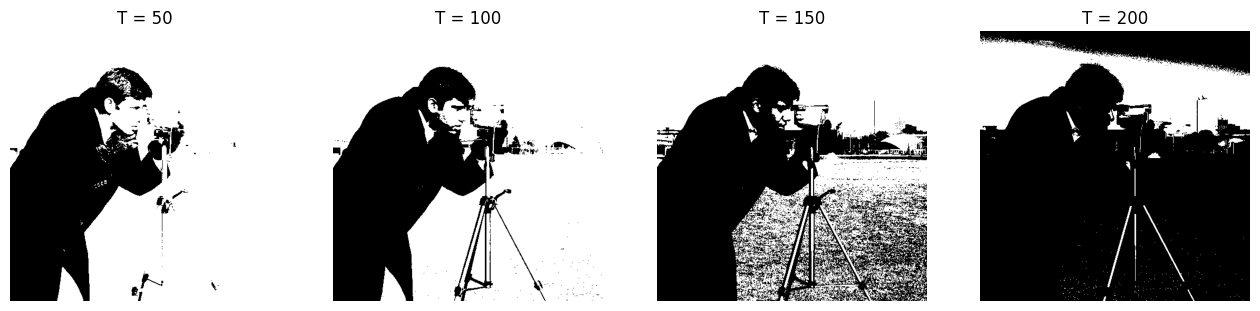

Otsu threshold picked: 102.0


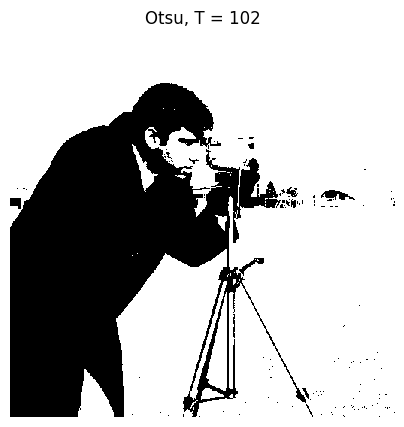

Identical: True | unique: [0 1] | white fraction: 0.6403312683105469
Binary @ 1 bit/pixel: 32768.0 bytes
B.nbytes (NumPy)    : 262144 bytes


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, T_ in zip(axes, [50, 100, 150, 200]):
    ax.imshow((I > T_).astype(np.uint8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"T = {T_}"); ax.axis("off")
plt.show()
# 1. The man's coat/camera are very dark, the sky is bright grey: T ~ 100-150
#    separates them best. T=50 keeps almost everything white (too low),
#    T=200 turns almost everything black (too high).

# 2. Otsu
T_otsu, B_otsu = cv2.threshold(I, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold picked:", T_otsu)
show(B_otsu, f"Otsu, T = {T_otsu:.0f}")

# 3. Storage of a binary image
T = 128
B = (I > T).astype(np.uint8)
_, B_cv = cv2.threshold(I, T, 1, cv2.THRESH_BINARY)
print("Identical:", np.array_equal(B, B_cv), "| unique:", np.unique(B),
      "| white fraction:", B.mean())
print("Binary @ 1 bit/pixel:", storage_bytes(M, N, 1), "bytes")   # 32768
print("B.nbytes (NumPy)    :", B.nbytes, "bytes")                  # 262144
# Difference: NumPy's smallest dtype is 1 byte (8 bits) per element, so each
# 1-bit pixel is stored in a full byte -> 8x more. Packing needs np.packbits.


# Task 4 - Colour channels



=== Task 4 ===
Shape: (512, 512, 3) dtype: uint8 Pixel(0,0): [154 147 151]


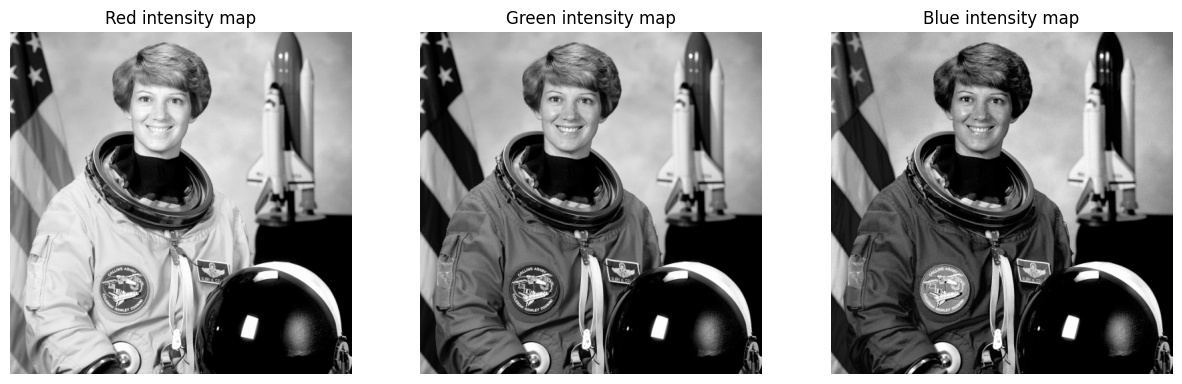

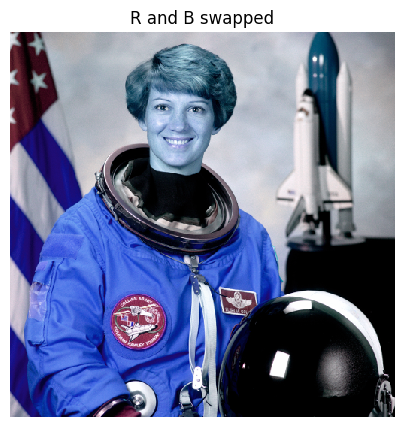

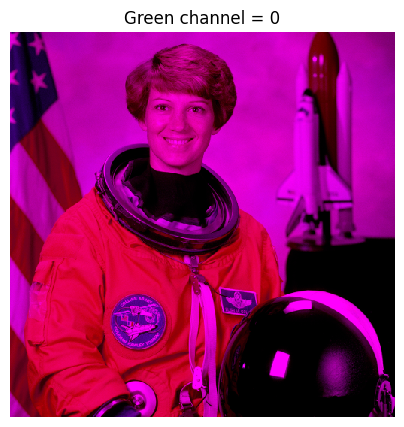

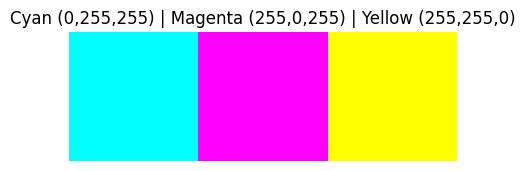

In [6]:
print("\n=== Task 4 ===")
print("Shape:", C.shape, "dtype:", C.dtype, "Pixel(0,0):", C[0, 0])
R, G, Bc = C[:, :, 0], C[:, :, 1], C[:, :, 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ch, name in zip(axes, [R, G, Bc], ["Red", "Green", "Blue"]):
    ax.imshow(ch, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name} intensity map"); ax.axis("off")
plt.show()

# 1. swap R and B
show(C[:, :, ::-1], "R and B swapped")
# Observation: skin looks blue/grey, blue things look orange/red. This is what
# you see when OpenCV's BGR image (cv2.imread) is shown by Matplotlib (RGB).

# 2. green = 0
noG = C.copy(); noG[:, :, 1] = 0
show(noG, "Green channel = 0")
# Remaining colours: only mixes of red and blue -> red, blue, magenta, black.
# Yellow/green/cyan/white lose their green and turn red/blue/magenta.

# 3. CMY stripes
stripes = np.zeros((100, 300, 3), dtype=np.uint8)
stripes[:, 0:100]   = [0, 255, 255]   # cyan
stripes[:, 100:200] = [255, 0, 255]   # magenta
stripes[:, 200:300] = [255, 255, 0]   # yellow
show(stripes, "Cyan (0,255,255) | Magenta (255,0,255) | Yellow (255,255,0)")


# Task 5 - Colour spaces



=== Task 5 ===
Max |weighted - OpenCV| = 1
H range: 0 - 179 | S: 0 - 255 | V: 0 - 255


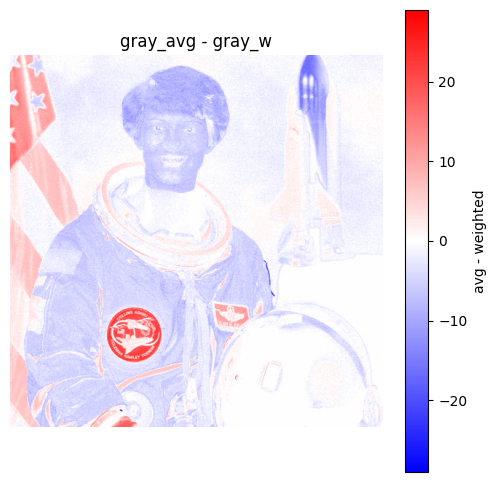

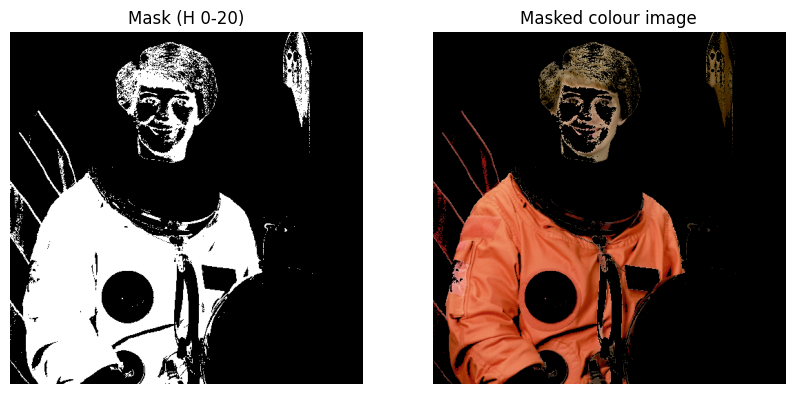

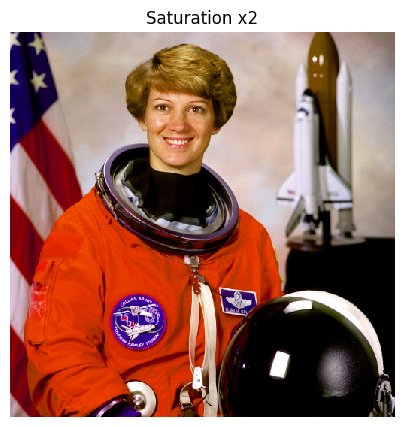

In [7]:
print("\n=== Task 5 ===")
Cf = C.astype(np.float64)
gray_avg = Cf.mean(axis=2).astype(np.uint8)
gray_w = (0.299 * Cf[:, :, 0] + 0.587 * Cf[:, :, 1] + 0.114 * Cf[:, :, 2]).round().astype(np.uint8)
gray_cv = cv2.cvtColor(C, cv2.COLOR_RGB2GRAY)
print("Max |weighted - OpenCV| =", np.abs(gray_w.astype(int) - gray_cv.astype(int)).max())

hsv = cv2.cvtColor(C, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(hsv)
print("H range:", H.min(), "-", H.max(), "| S:", S.min(), "-", S.max(), "| V:", V.min(), "-", V.max())

# 1. difference map
diff = gray_avg.astype(int) - gray_w.astype(int)
plt.figure(figsize=(6, 6))
m = np.abs(diff).max()
plt.imshow(diff, cmap="bwr", vmin=-m, vmax=m); plt.colorbar(label="avg - weighted")
plt.title("gray_avg - gray_w"); plt.axis("off"); plt.show()
# Largest differences: strongly saturated pure-colour regions. The eye is most
# sensitive to green (0.587), least to blue (0.114). Averaging treats them
# equally, so bright blue areas look too light (red in map) and green areas too
# dark (blue in map). Neutral grey areas (R=G=B) show no difference.

# 2. red/orange mask (low hue; OpenCV H in [0,179], red wraps around 0/179)
lower, upper = np.array([0, 80, 60]), np.array([20, 255, 255])
mask = cv2.inRange(hsv, lower, upper)
masked = cv2.bitwise_and(C, C, mask=mask)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(mask, cmap="gray"); ax[0].set_title("Mask (H 0-20)")
ax[1].imshow(masked); ax[1].set_title("Masked colour image")
for a in ax: a.axis("off")
plt.show()

# 3. double saturation
hsv2 = hsv.copy()
hsv2[:, :, 1] = np.clip(hsv[:, :, 1].astype(int) * 2, 0, 255).astype(np.uint8)
show(cv2.cvtColor(hsv2, cv2.COLOR_HSV2RGB), "Saturation x2")

# Task 6 - Resolution



=== Task 6 ===


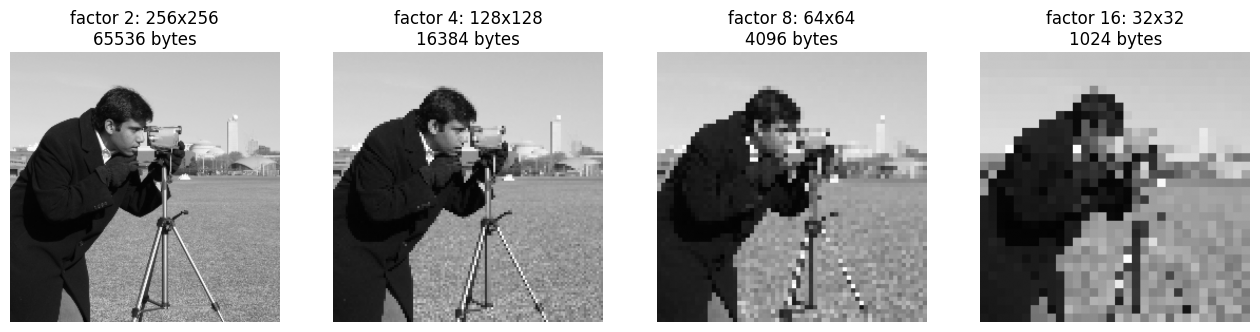

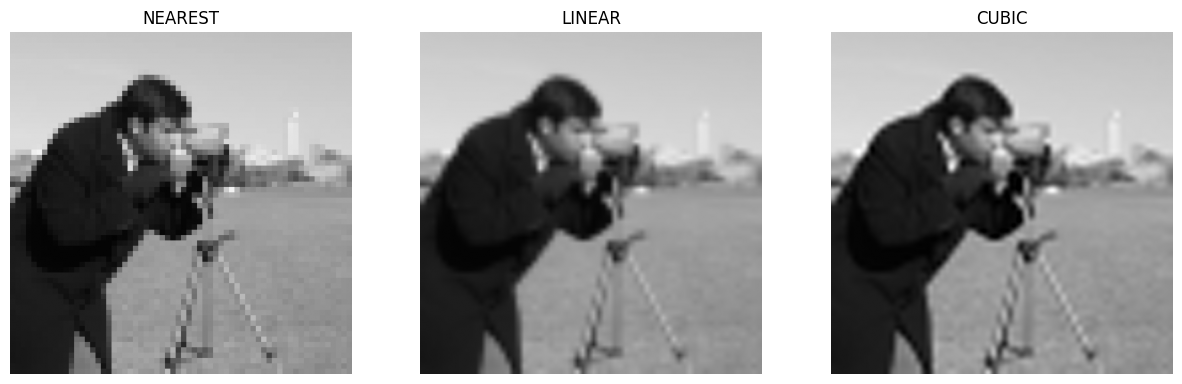

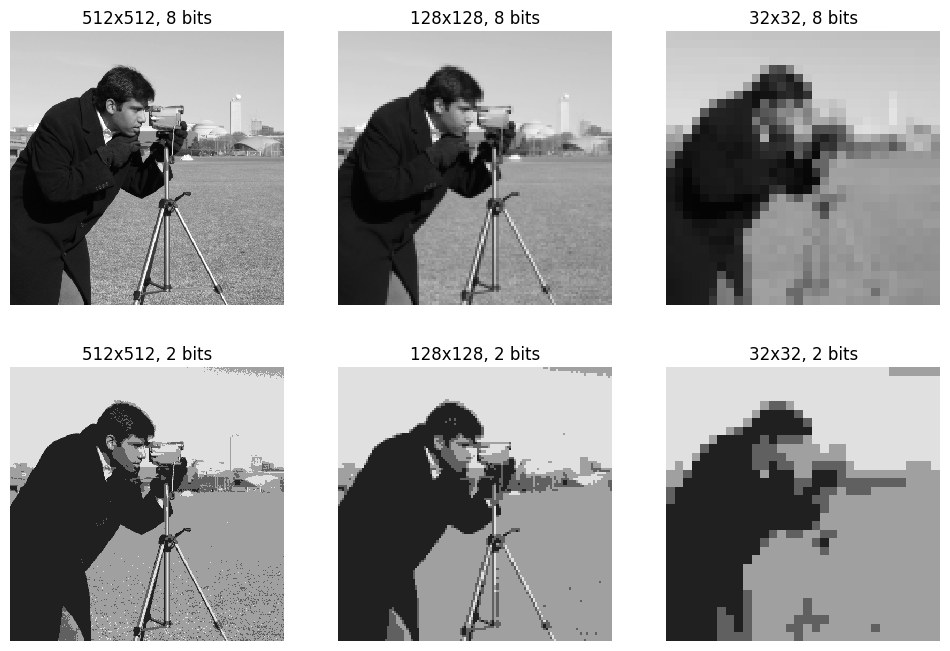

In [8]:
print("\n=== Task 6 ===")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, [2, 4, 8, 16]):
    small = I[::f, ::f]
    back = cv2.resize(small, (N, M), interpolation=cv2.INTER_NEAREST)
    ax.imshow(back, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"factor {f}: {small.shape[0]}x{small.shape[1]}\n{small.nbytes} bytes")
    ax.axis("off")
plt.show()

# 1. down to 64x64, up with three interpolations
small64 = cv2.resize(I, (64, 64), interpolation=cv2.INTER_AREA)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, flag) in zip(axes, [("NEAREST", cv2.INTER_NEAREST),
                                   ("LINEAR", cv2.INTER_LINEAR),
                                   ("CUBIC", cv2.INTER_CUBIC)]):
    ax.imshow(cv2.resize(small64, (512, 512), interpolation=flag),
              cmap="gray", vmin=0, vmax=255)
    ax.set_title(name); ax.axis("off")
plt.show()
# No: interpolation does not recover lost detail. Down-sampling discarded the
# high-frequency information; interpolation only guesses in-between values from
# neighbours. NEAREST gives blocks, LINEAR/CUBIC give smoother but blurry images.

# 2. 2x3 grid: sizes {512,128,32} x bit depths {8,2}
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for r, k in enumerate([8, 2]):
    for c, s in enumerate([512, 128, 32]):
        img = cv2.resize(I, (s, s), interpolation=cv2.INTER_AREA)
        img = quantize(img, k)
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axes[r, c].set_title(f"{s}x{s}, {k} bits"); axes[r, c].axis("off")
plt.show()

# Task 7 - Bayer



=== Task 7 ===


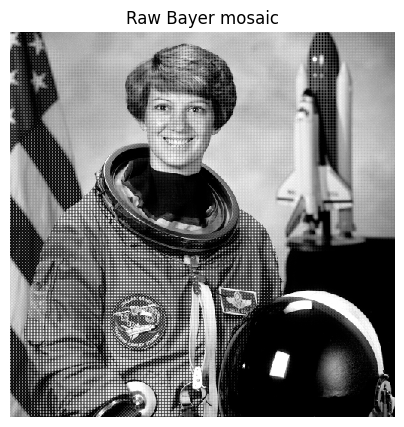

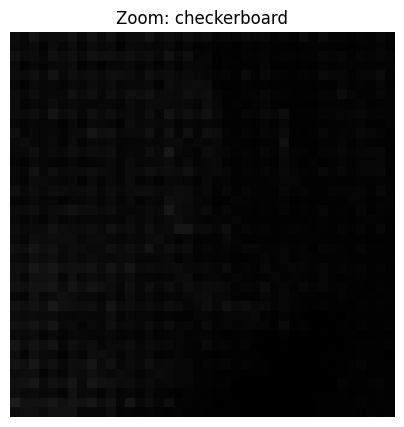

Mean absolute error after demosaicing: 2.85


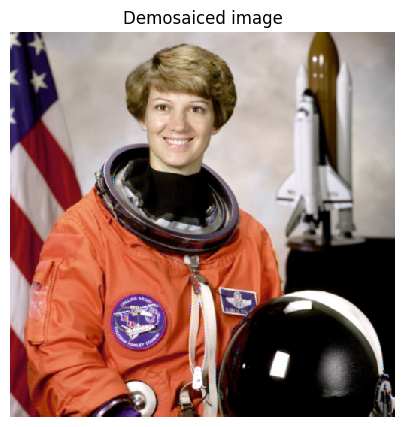

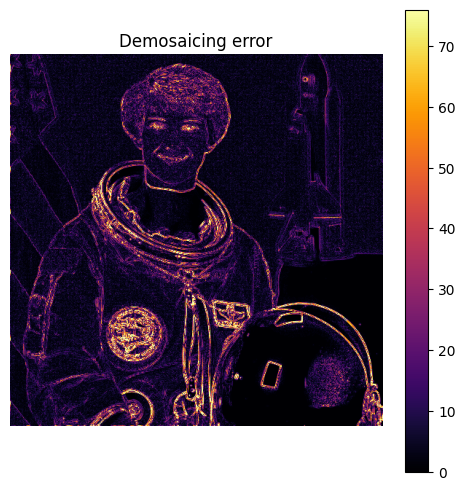

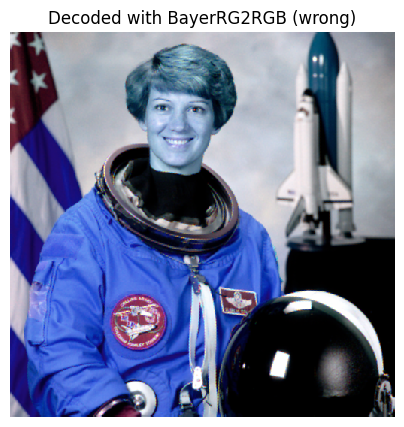

In [9]:
print("\n=== Task 7 ===")
h, w, _ = C.shape
mosaic = np.zeros((h, w), dtype=np.uint8)
mosaic[0::2, 0::2] = C[0::2, 0::2, 0]   # R
mosaic[0::2, 1::2] = C[0::2, 1::2, 1]   # G
mosaic[1::2, 0::2] = C[1::2, 0::2, 1]   # G
mosaic[1::2, 1::2] = C[1::2, 1::2, 2]   # B
show(mosaic, "Raw Bayer mosaic")
show(mosaic[200:240, 200:240], "Zoom: checkerboard")

rebuilt = cv2.cvtColor(mosaic, cv2.COLOR_BayerBG2RGB)
err = np.abs(rebuilt.astype(int) - C.astype(int)).mean()
print(f"Mean absolute error after demosaicing: {err:.2f}")
show(rebuilt, "Demosaiced image")

# 1. The sensor measures 1 of 3 values per pixel -> 1/3 (33 %) of the full
#    colour information (R 25 %, G 50 %, B 25 % of the pixels).
# 2. error map
E = np.abs(rebuilt.astype(int) - C.astype(int)).sum(axis=2)
plt.figure(figsize=(6, 6))
plt.imshow(E, cmap="inferno", vmax=np.percentile(E, 99)); plt.colorbar()
plt.title("Demosaicing error"); plt.axis("off"); plt.show()
# Errors are largest at sharp edges and fine textures (hair, text, strong colour
# transitions): interpolation assumes neighbouring pixels are similar, which is
# false across an edge -> colour fringing / zipper artefacts. Smooth areas are fine.

# 3. wrong pattern
wrong = cv2.cvtColor(mosaic, cv2.COLOR_BayerRG2RGB)
show(wrong, "Decoded with BayerRG2RGB (wrong)")

# Task 8 - Bitmap vs vector



=== Task 8 ===


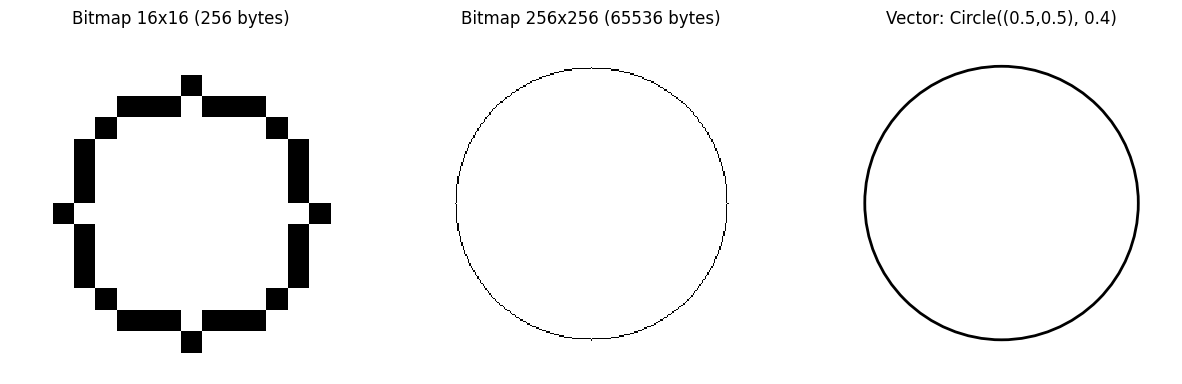

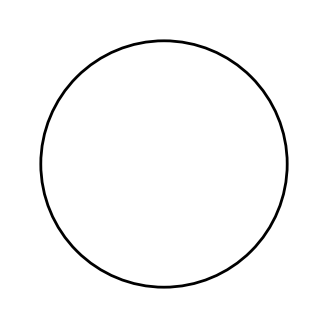

In [10]:
print("\n=== Task 8 ===")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
bitmaps = {}
for ax, size in zip(axes[:2], [16, 256]):
    canvas = np.full((size, size), 255, dtype=np.uint8)
    cv2.circle(canvas, (size // 2, size // 2), int(size * 0.4), 0, 1)
    bitmaps[size] = canvas
    ax.imshow(canvas, cmap="gray", interpolation="nearest")
    ax.set_title(f"Bitmap {size}x{size} ({canvas.nbytes} bytes)"); ax.axis("off")
axes[2].add_patch(plt.Circle((0.5, 0.5), 0.4, fill=False, lw=2))
axes[2].set_xlim(0, 1); axes[2].set_ylim(0, 1)
axes[2].set_aspect("equal"); axes[2].axis("off")
axes[2].set_title("Vector: Circle((0.5,0.5), 0.4)")

# save vector figure alone as SVG, bitmap as PNG
fig_v, ax_v = plt.subplots(figsize=(4, 4))
ax_v.add_patch(plt.Circle((0.5, 0.5), 0.4, fill=False, lw=2))
ax_v.set_xlim(0, 1); ax_v.set_ylim(0, 1); ax_v.set_aspect("equal"); ax_v.axis("off")
fig_v.savefig("circle.svg")
cv2.imwrite("circle.png", bitmaps[16])
plt.show()

# Task 9 - describe_image


In [11]:
def describe_image(img, name="image"):
    vals = np.unique(img)
    levels = len(vals)
    if img.ndim == 2 and np.isin(vals, [0, 1]).all() or \
       img.ndim == 2 and np.isin(vals, [0, 255]).all():
        kind = "binary"
    elif img.ndim == 2:
        kind = "grayscale"
    else:
        kind = "color"
    ch = 1 if img.ndim == 2 else img.shape[2]
    k = max(1, int(np.ceil(np.log2(levels))))
    b = img.shape[0] * img.shape[1] * ch * k / 8
    print(f"+--- ID card: {name} " + "-" * 20)
    print(f"| type    : {kind}")
    print(f"| size    : {img.shape[0]} x {img.shape[1]}" + (f" x {ch} channels" if ch > 1 else ""))
    print(f"| dtype   : {img.dtype}")
    print(f"| levels  : {levels} distinct | min {img.min()} | max {img.max()} | mean {img.mean():.2f}")
    print(f"| min k   : {k} bit(s)/channel -> {b:.0f} bytes ({b/1024:.1f} KiB)")
    print("+" + "-" * 40)


print("\n=== Task 9 ===")
describe_image(I, "I (camera)")
describe_image(quantize(I, 2), "quantize(I, 2)")
describe_image(B, "B (binary, T=128)")
describe_image(C, "C (astronaut)")
describe_image(mosaic, "mosaic")


=== Task 9 ===
+--- ID card: I (camera) --------------------
| type    : grayscale
| size    : 512 x 512
| dtype   : uint8
| levels  : 256 distinct | min 0 | max 255 | mean 129.06
| min k   : 8 bit(s)/channel -> 262144 bytes (256.0 KiB)
+----------------------------------------
+--- ID card: quantize(I, 2) --------------------
| type    : grayscale
| size    : 512 x 512
| dtype   : uint8
| levels  : 4 distinct | min 32 | max 224 | mean 137.45
| min k   : 2 bit(s)/channel -> 65536 bytes (64.0 KiB)
+----------------------------------------
+--- ID card: B (binary, T=128) --------------------
| type    : binary
| size    : 512 x 512
| dtype   : uint8
| levels  : 2 distinct | min 0 | max 1 | mean 0.64
| min k   : 1 bit(s)/channel -> 32768 bytes (32.0 KiB)
+----------------------------------------
+--- ID card: C (astronaut) --------------------
| type    : color
| size    : 512 x 512 x 3 channels
| dtype   : uint8
| levels  : 256 distinct | min 0 | max 255 | mean 114.60
| min k   : 8 bit(

# Task 10 - Pixel art + "life of an image"



=== Task 10 ===


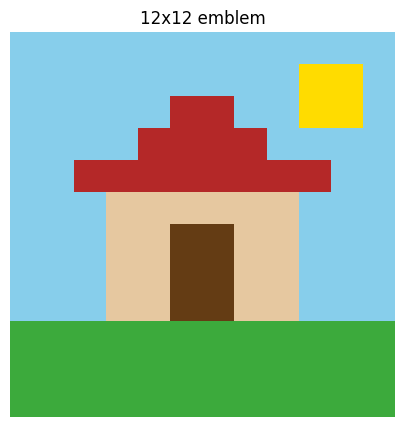

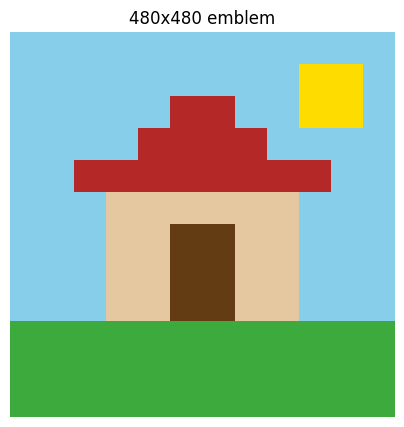

+--- ID card: emblem 12x12 --------------------
| type    : color
| size    : 12 x 12 x 3 channels
| dtype   : uint8
| levels  : 15 distinct | min 0 | max 255 | mean 152.07
| min k   : 4 bit(s)/channel -> 216 bytes (0.2 KiB)
+----------------------------------------
+--- ID card: emblem 480x480 --------------------
| type    : color
| size    : 480 x 480 x 3 channels
| dtype   : uint8
| levels  : 15 distinct | min 0 | max 255 | mean 152.07
| min k   : 4 bit(s)/channel -> 345600 bytes (337.5 KiB)
+----------------------------------------


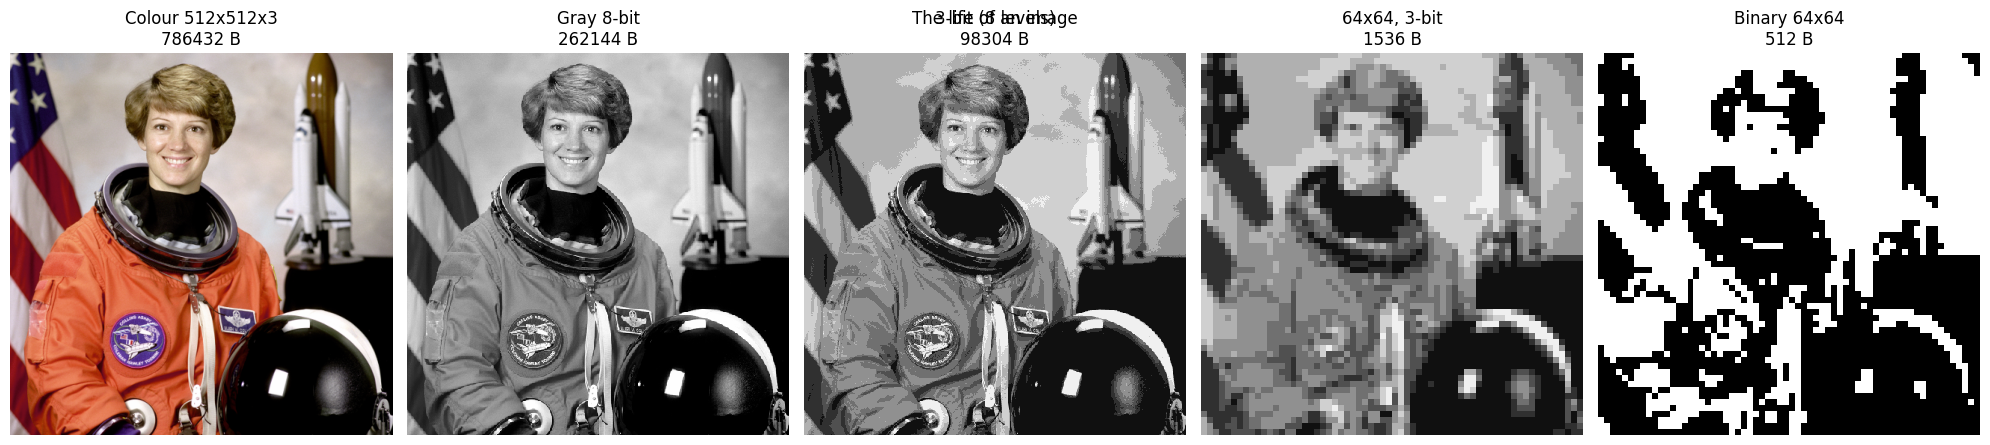

In [12]:
print("\n=== Task 10 ===")
# 1. 12x12x3 emblem: a house with sun (>= 4 colours)
sky, sun, wall, roof, door, grass = ([135, 206, 235], [255, 220, 0], [230, 200, 160],
                                     [180, 40, 40], [100, 60, 20], [60, 170, 60])
em = np.zeros((12, 12, 3), dtype=np.uint8)
em[:] = sky
em[9:, :] = grass
em[1:3, 9:11] = sun                      # sun
em[5:9, 3:9] = wall                      # house body
for i, r in enumerate(range(2, 5)):      # triangular roof
    em[r, 5 - i:7 + i] = roof
em[4, 2:10] = roof
em[6:9, 5:7] = door                      # door
show(em, "12x12 emblem")

# 2. enlarge, save, describe
big = cv2.resize(em, (480, 480), interpolation=cv2.INTER_NEAREST)
cv2.imwrite("emblem.png", cv2.cvtColor(big, cv2.COLOR_RGB2BGR))   # cv2 expects BGR
show(big, "480x480 emblem")
describe_image(em, "emblem 12x12")
describe_image(big, "emblem 480x480")
# Same distinct colours, same type; only the size (and storage) grows 1600x.

# 3. Bonus: "The life of an image"
gray = cv2.cvtColor(C, cv2.COLOR_RGB2GRAY)
g3 = quantize(gray, 3)
g64 = cv2.resize(g3, (64, 64), interpolation=cv2.INTER_AREA)
g64 = quantize(g64, 3)
bin64 = (g64 > 128).astype(np.uint8)
stages = [
    (C, f"Colour 512x512x3\n{int(storage_bytes(512, 512, 8, 3))} B", None),
    (gray, f"Gray 8-bit\n{int(storage_bytes(512, 512, 8))} B", "gray"),
    (g3, f"3-bit (8 levels)\n{int(storage_bytes(512, 512, 3))} B", "gray"),
    (g64, f"64x64, 3-bit\n{int(storage_bytes(64, 64, 3))} B", "gray"),
    (bin64, f"Binary 64x64\n{int(storage_bytes(64, 64, 1))} B", "gray"),
]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, (im, t, cm) in zip(axes, stages):
    if cm:
        vmax = 1 if im.max() <= 1 else 255
        ax.imshow(im, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
    else:
        ax.imshow(im)
    ax.set_title(t); ax.axis("off")
fig.suptitle("The life of an image")
plt.tight_layout()
plt.show()